# PC3 - Deep Learning - Notebook 3
### Mucha Alvarez Diego Fabrizio - u202317069

# 03 · Transfer Learning

Usaremos ResNet-18 con pesos de ImageNet y compararemos tres formas de entrenarla.
Ejecuta antes los notebooks 01 y 02 para tener los datos y los resultados de LeNet/VGG.

## Preparación

Sube la carpeta `PC3_Deep_Learning` a **Mi unidad** de Google Drive, incluyendo
`data/raw/` con las imágenes descargadas. No hace falta subir `.venv`.
Usaremos esa carpeta en los tres notebooks. Ejecútalos en orden: **01 → 02 → 03**.
Para los notebooks 02 y 03, activa una GPU en Colab.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

%cd /content/drive/MyDrive/PC3_Deep_Learning
%pip install -q -r requirements.txt

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image as MostrarImagen
from src.utils import seed_everything

seed_everything(42)

## Tres estrategias

| Estrategia | Capas que se entrenan | LR |
| --- | --- | --- |
| Feature extraction | Solo la capa final | 0.001 |
| Fine-tuning parcial | layer3, layer4 y capa final | 0.0001 |
| Fine-tuning total | Todas | 0.00001 |

En el ajuste parcial se congelan la entrada y los bloques layer1 y layer2.
Las estadísticas BN de las capas congeladas tampoco cambian.
Usamos imágenes de 224×224, normalización ImageNet y Adam.

In [2]:
from src.models import build_model, parameter_counts
from src.train import DEFAULT_SETTINGS, run_suite
from src.utils import export_results

parametros = []
for estrategia in ["feature", "partial", "full"]:
    seed_everything(42)
    red = build_model("resnet18", strategy=estrategia, pretrained=True)
    parametros.append({"estrategia": estrategia, **parameter_counts(red)})
display(pd.DataFrame(parametros))

/home/diegomucha/me/programming/projects/PC3_Deep_Learning/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /home/diegomucha/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:04<00:00, 11.6MB/s]


,estrategia,parameters,trainable_parameters
0,feature,11178564,2052
1,partial,11178564,10495492
2,full,11178564,11178564


## Entrenar las tres estrategias

Usamos GPU y 5 épocas por estrategia. Las tres usan las mismas particiones,
semilla, batch y aumentos. La primera descarga de pesos necesita Internet.

In [4]:
resultados_transfer = run_suite(DEFAULT_SETTINGS, "transfer", device="cpu")
display(resultados_transfer[["name", "trainable_parameters", "mean_train_seconds", "best_val_accuracy", "test_accuracy", "test_f1_macro"]])

resnet18_feature_seed42: 100%|██████████| 5/5 [24:19<00:00, 291.99s/it]


resnet18_feature_seed42: completed; mejor val=0.5225903614457831; test=0.4085243264977885


resnet18_partial_seed42: 100%|██████████| 5/5 [37:33<00:00, 450.71s/it]


resnet18_partial_seed42: completed; mejor val=0.998995983935743; test=0.8057901085645356


resnet18_full_seed42: 100%|██████████| 5/5 [1:02:14<00:00, 746.91s/it]


resnet18_full_seed42: completed; mejor val=0.9909638554216867; test=0.8532368315239244


,name,trainable_parameters,mean_train_seconds,best_val_accuracy,test_accuracy,test_f1_macro
0,resnet18_feature_seed42,2052,230.354086,0.522590,0.408524,0.377346
1,resnet18_partial_seed42,10495492,381.326316,0.998996,0.805790,0.805035
2,resnet18_full_seed42,11178564,674.702758,0.990964,0.853237,0.855701


## Comparar con el mejor modelo desde cero

Elegimos el mejor LeNet/VGG por su accuracy de validación. Si hay empate,
usamos la menor pérdida. No se usan los ensayos de LR alta para esta selección.
Las tablas muestran accuracy entre 0 y 1.

,name,parameters,trainable_parameters,mean_train_seconds,best_val_accuracy,test_accuracy,test_f1_macro,epoch_to_80_val,status
0,lenet_bn_scratch_seed42,338020,338020,19.319858,0.586847,0.398874,0.403799,NaN,completed
1,lenet_scratch_seed42,337976,337976,18.914268,0.712851,0.486530,0.488270,NaN,completed
2,resnet18_feature_seed42,11178564,2052,230.354086,0.522590,0.408524,0.377346,NaN,completed
3,resnet18_full_seed42,11178564,11178564,674.702758,0.990964,0.853237,0.855701,2.0,completed
4,resnet18_partial_seed42,11178564,10495492,381.326316,0.998996,0.805790,0.805035,1.0,completed
5,vgg11_scratch_seed42,2963396,2963396,65.741473,0.251004,0.250905,0.100289,NaN,completed


,name,parameters,trainable_parameters,mean_train_seconds,best_val_accuracy,test_accuracy,test_f1_macro,epoch_to_80_val,status
0,lenet_scratch_seed42,337976,337976,18.914268,0.712851,0.486530,0.488270,NaN,completed
1,resnet18_feature_seed42,11178564,2052,230.354086,0.522590,0.408524,0.377346,NaN,completed
2,resnet18_full_seed42,11178564,11178564,674.702758,0.990964,0.853237,0.855701,2.0,completed
3,resnet18_partial_seed42,11178564,10495492,381.326316,0.998996,0.805790,0.805035,1.0,completed


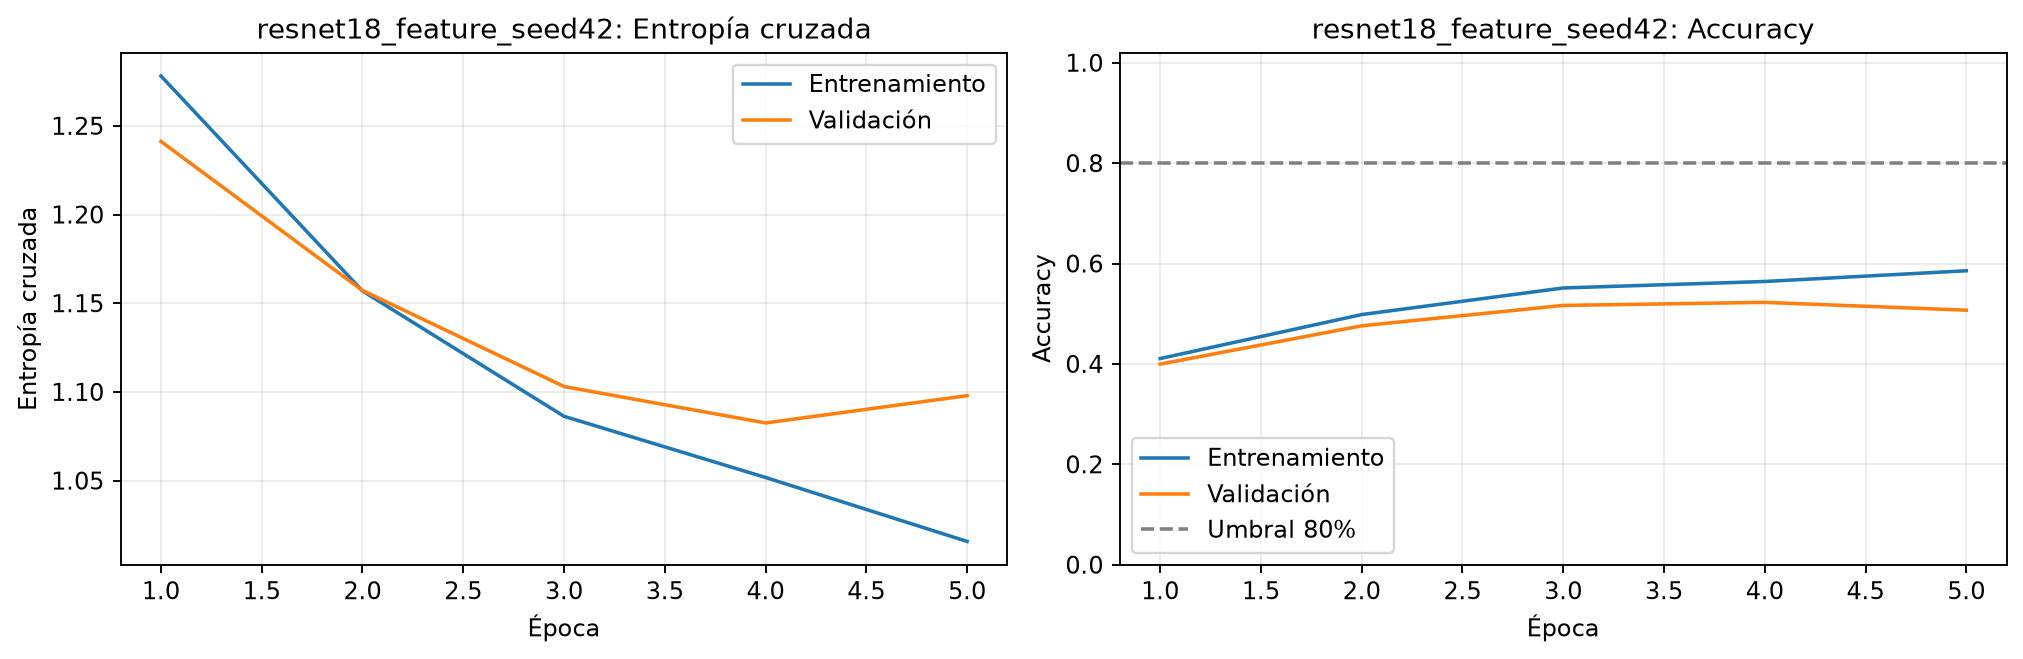

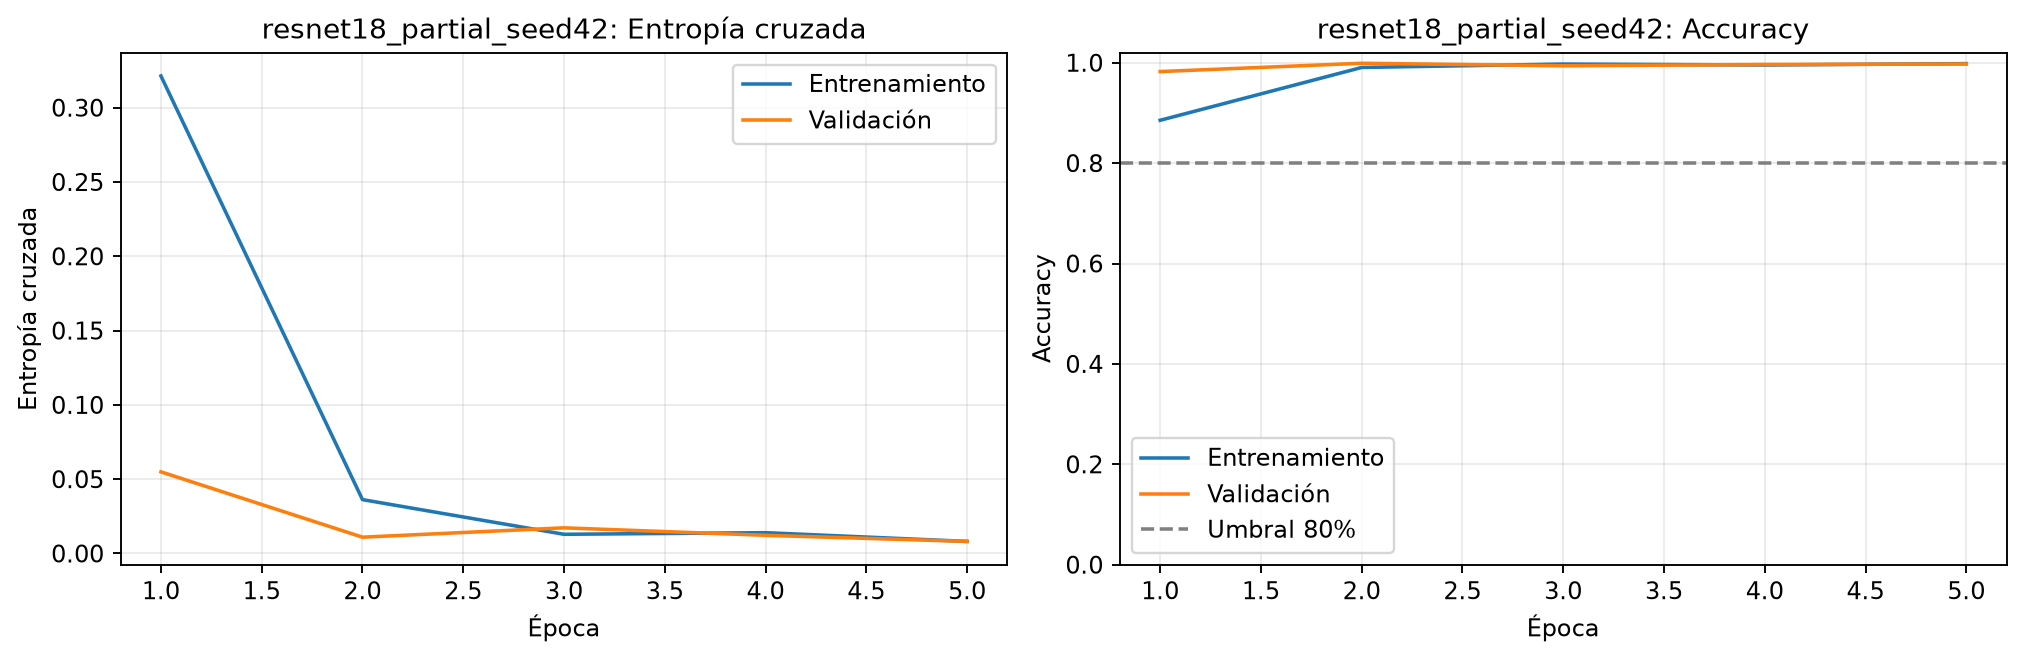

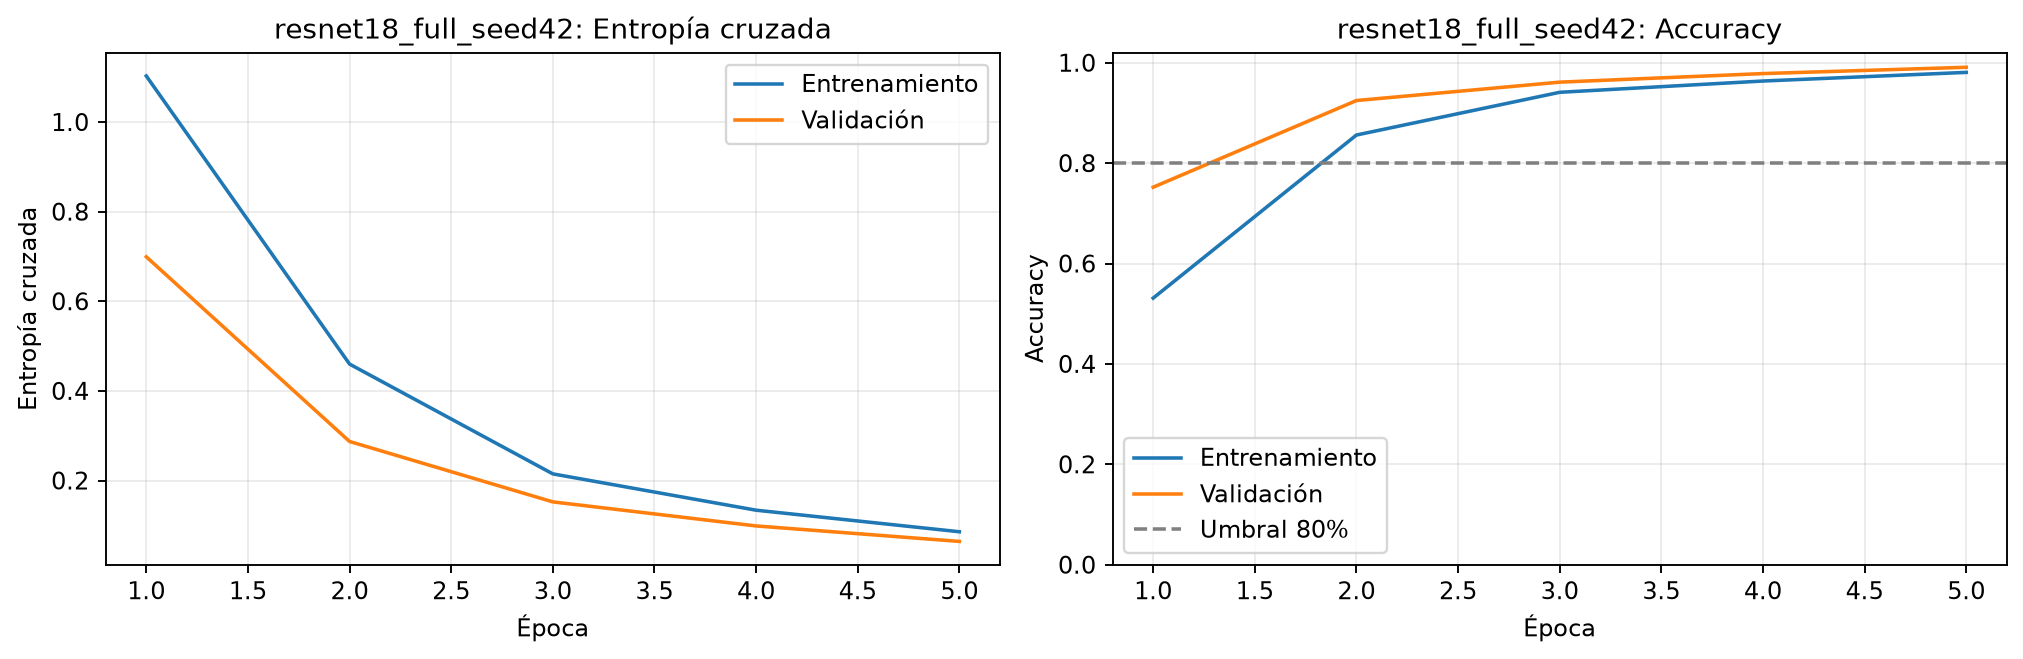

In [5]:
display(export_results("results", "README.md"))
display(pd.read_csv("results/tables/transfer_vs_best_scratch.csv"))

for estrategia in ["feature", "partial", "full"]:
    display(MostrarImagen(filename=f"results/figures/resnet18_{estrategia}_seed42_curves.png"))

## Errores del mejor modelo

El mejor modelo se elige por validación. Esta matriz muestra sus errores en test.
Mira qué clases confunde más y el recall de cada clase.
`all_seven_completed` debe ser `True`: indica que terminaron los siete modelos principales.

{'name': 'resnet18_partial_seed42',
 'selection': 'Mayor accuracy de validación; desempate por menor pérdida',
 'all_seven_completed': False}

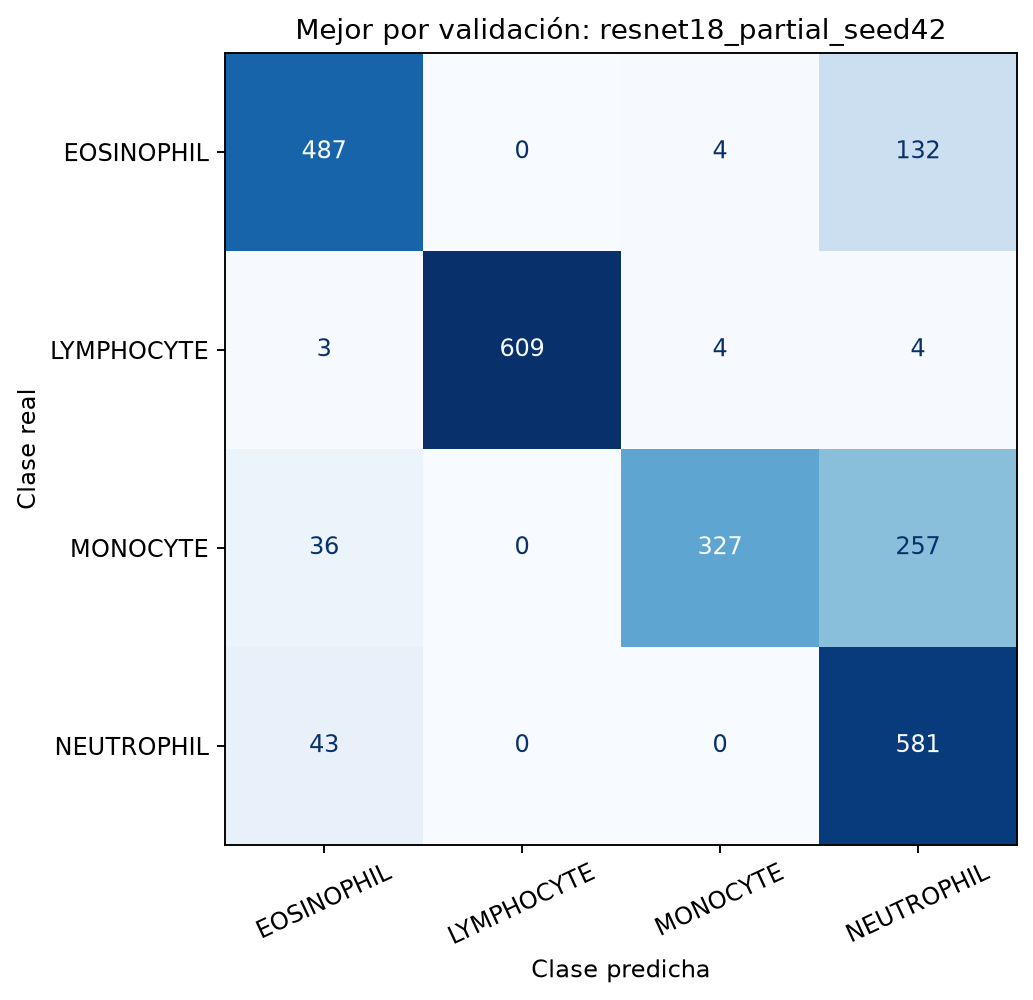

,precision,recall,f1-score,support
EOSINOPHIL,0.855888,0.781701,0.817114,623.0
LYMPHOCYTE,1.000000,0.982258,0.991050,620.0
MONOCYTE,0.976119,0.527419,0.684817,620.0
NEUTROPHIL,0.596509,0.931090,0.727159,624.0


In [6]:
with open("results/tables/best_model_seed42.json") as archivo:
    mejor = json.load(archivo)
display(mejor)
display(MostrarImagen(filename="results/figures/best_confusion_seed42.png"))

with open("results/runs/" + mejor["name"] + "/classification_report.json") as archivo:
    reporte = json.load(archivo)
display(pd.DataFrame(reporte).T.loc[["EOSINOPHIL", "LYMPHOCYTE", "MONOCYTE", "NEUTROPHIL"]])

## Comentarios

- ¿Qué estrategia funcionó mejor y cuánto tardó?
- ¿Cuál recomendarías con pocos datos médicos? Usa accuracy, macro-F1 y recall para justificar.
- ¿Hay señales de sobreajuste?

**Respuesta:** En test, el *fine-tuning* total fue la estrategia con mejor desempeño: obtuvo accuracy de 0.853 y macro-F1 de 0.856. Su costo fue el mayor tiempo de entrenamiento: 674.7 s por época en promedio, aproximadamente 56.2 min en las 5 épocas. El ajuste parcial fue más rápido (381.3 s por época; aproximadamente 31.8 min) y logró la mejor accuracy de validación (0.999), por lo que fue el modelo seleccionado con el criterio de validación, pero su desempeño en test fue menor (accuracy 0.806 y macro-F1 0.805). La extracción de características no fue suficiente (accuracy 0.409 y macro-F1 0.377).

Para pocos datos médicos recomendaría el *fine-tuning* total si se dispone del tiempo de cómputo, porque en este experimento generalizó mejor en test: accuracy 0.853 frente a 0.806 del ajuste parcial y macro-F1 0.856 frente a 0.805. También tuvo recalls más equilibrados: eosinófilos 0.838, linfocitos 1.000, monocitos 0.708 y neutrófilos 0.867; el ajuste parcial bajó especialmente en monocitos (0.527), aunque fue alto en linfocitos (0.982) y neutrófilos (0.931). Si el tiempo de entrenamiento fuera una restricción importante, el ajuste parcial sería una alternativa razonable, pero convendría revisar su bajo recall de monocitos.

Sí hay señales de posible sobreajuste o, al menos, de una brecha de generalización: el ajuste parcial alcanzó 0.999 de accuracy de validación, pero solo 0.806 en test; en el ajuste total la diferencia fue de 0.991 a 0.853. Además, la pérdida de validación del ajuste parcial aumentó después de la época 2 mientras la pérdida de entrenamiento siguió bajando. Estas conclusiones son preliminares: harían falta más semillas y una evaluación externa por paciente o centro.

Al comparar con LeNet/VGG también cambian la resolución, el optimizador y el
preentrenamiento. Entre las estrategias de ResNet cambia la LR. Por eso no podemos
atribuir toda diferencia a una sola causa. Además, faltan pruebas con pacientes o centros nuevos.